# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

dataset_path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(dataset_path, "CarPrice_Assignment.csv"))

print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість стовпців (з урахуванням car_ID та price): {df.shape[1]}")
print(f"Кількість ознак без цільової змінної price: {df.shape[1] - 1}")

print("\nНазви стовпців:")
print(list(df.columns))

print("\nТипи даних:")
print(df.dtypes)

TARGET = "price"
print(f"\nЦільова змінна: {TARGET} (неперервна величина - ціна автомобіля)")

print("\nПерші 5 рядків:")
display(df.head())

print("\nОсновні статистичні характеристики числових ознак:")
display(df.describe().T)

print("\nСтатистика категоріальних ознак:")
display(df.describe(include="object").T)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість об'єктів (рядків): 205
Кількість стовпців (з урахуванням car_ID та price): 26
Кількість ознак без цільової змінної price: 25

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           ob

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



Основні статистичні характеристики числових ознак:


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17



Статистика категоріальних ознак:


,count,unique,top,freq
CarName,205,147,peugeot 504,6
fueltype,205,2,gas,185
aspiration,205,2,std,168
doornumber,205,2,four,115
carbody,205,5,sedan,96
drivewheel,205,3,fwd,120
enginelocation,205,2,front,202
enginetype,205,7,ohc,148
cylindernumber,205,7,four,159
fuelsystem,205,8,mpfi,94


**Висновок до етапу 1.** Датасет містить 205 автомобілів і 26 стовпців. Цільова змінна `price` неперервна, тому задача належить до регресії. Є числові та категоріальні (`object`) ознаки, а `car_ID` — службовий ідентифікатор. Числові ознаки мають різні масштаби (наприклад, `curbweight` у тисячах, а `boreratio` близько 3), тому знадобиться масштабування.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
missing_count = df.isna().sum()
missing_table = pd.DataFrame({
    "Пропущено": missing_count,
    "Частка, %": (missing_count / len(df) * 100).round(2),
})
print("Пропущені значення (показано лише стовпці з пропусками):")
if missing_count.sum() > 0:
    display(missing_table[missing_table["Пропущено"] > 0])
else:
    print("Пропущених значень немає.")

full_duplicates = df.duplicated().sum()
content_duplicates = df.drop(columns="car_ID").duplicated().sum()
print(f"\nПовних дублікатів рядків: {full_duplicates}")
print(f"Дублікатів за змістовими ознаками (без car_ID): {content_duplicates}")

unique_table = df.nunique().sort_values().to_frame("Унікальних значень")
unique_table["Тип"] = df.dtypes[unique_table.index].astype(str)
print("\nКількість унікальних значень в ознаках:")
display(unique_table)

n_car_names = df["CarName"].nunique()
brand_fixes = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
}
df["CarBrand"] = df["CarName"].str.split().str[0].str.lower().replace(brand_fixes)
df = df.drop(columns="CarName")
print(f"\nУнікальних значень CarName було: {n_car_names}; унікальних марок CarBrand тепер: {df['CarBrand'].nunique()}")
print("Марки:", sorted(df["CarBrand"].unique()))

Пропущені значення (показано лише стовпці з пропусками):
Пропущених значень немає.

Повних дублікатів рядків: 0
Дублікатів за змістовими ознаками (без car_ID): 0

Кількість унікальних значень в ознаках:


,Унікальних значень,Тип
fueltype,2,object
aspiration,2,object
doornumber,2,object
enginelocation,2,object
drivewheel,3,object
carbody,5,object
symboling,6,int64
cylindernumber,7,object
enginetype,7,object
fuelsystem,8,object



Унікальних значень CarName було: 147; унікальних марок CarBrand тепер: 22
Марки: ['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']


**Висновок до етапу 2.** Пропущених значень немає, повних дублікатів і змістових дублікатів (без `car_ID`) також немає, тому видаляти або заповнювати рядки не потрібно. Ознака `CarName` мала 147 унікальних значень, тому її замінено на марку `CarBrand` (22 марки). Інші категоріальні ознаки мають від 2 до 8 категорій, тому їх можна безпечно кодувати методом One-Hot.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df["car_ID"].copy()
print(f"Кількість car_ID: {car_ids.shape[0]}, усі унікальні: {car_ids.is_unique}")
print(f"Діапазон car_ID: {car_ids.min()} - {car_ids.max()}")

df_model = df.drop(columns="car_ID")
print(f"\nСтовпців у df_model: {df_model.shape[1]}; car_ID серед них: {'car_ID' in df_model.columns}")

print("\nПриклад збережених car_ID:")
display(car_ids.head().to_frame())

Кількість car_ID: 205, усі унікальні: True
Діапазон car_ID: 1 - 205

Стовпців у df_model: 25; car_ID серед них: False

Приклад збережених car_ID:


,car_ID
0,1
1,2
2,3
3,4
4,5


**Висновок до етапу 3.** `car_ID` збережено окремо (`car_ids`) і виключено з даних для моделювання (`df_model`). Це запобігає хибним закономірностям на основі номера запису та дає змогу пізніше повернути ідентифікатор до таблиці прогнозів.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Числові змінні (разом з price): ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


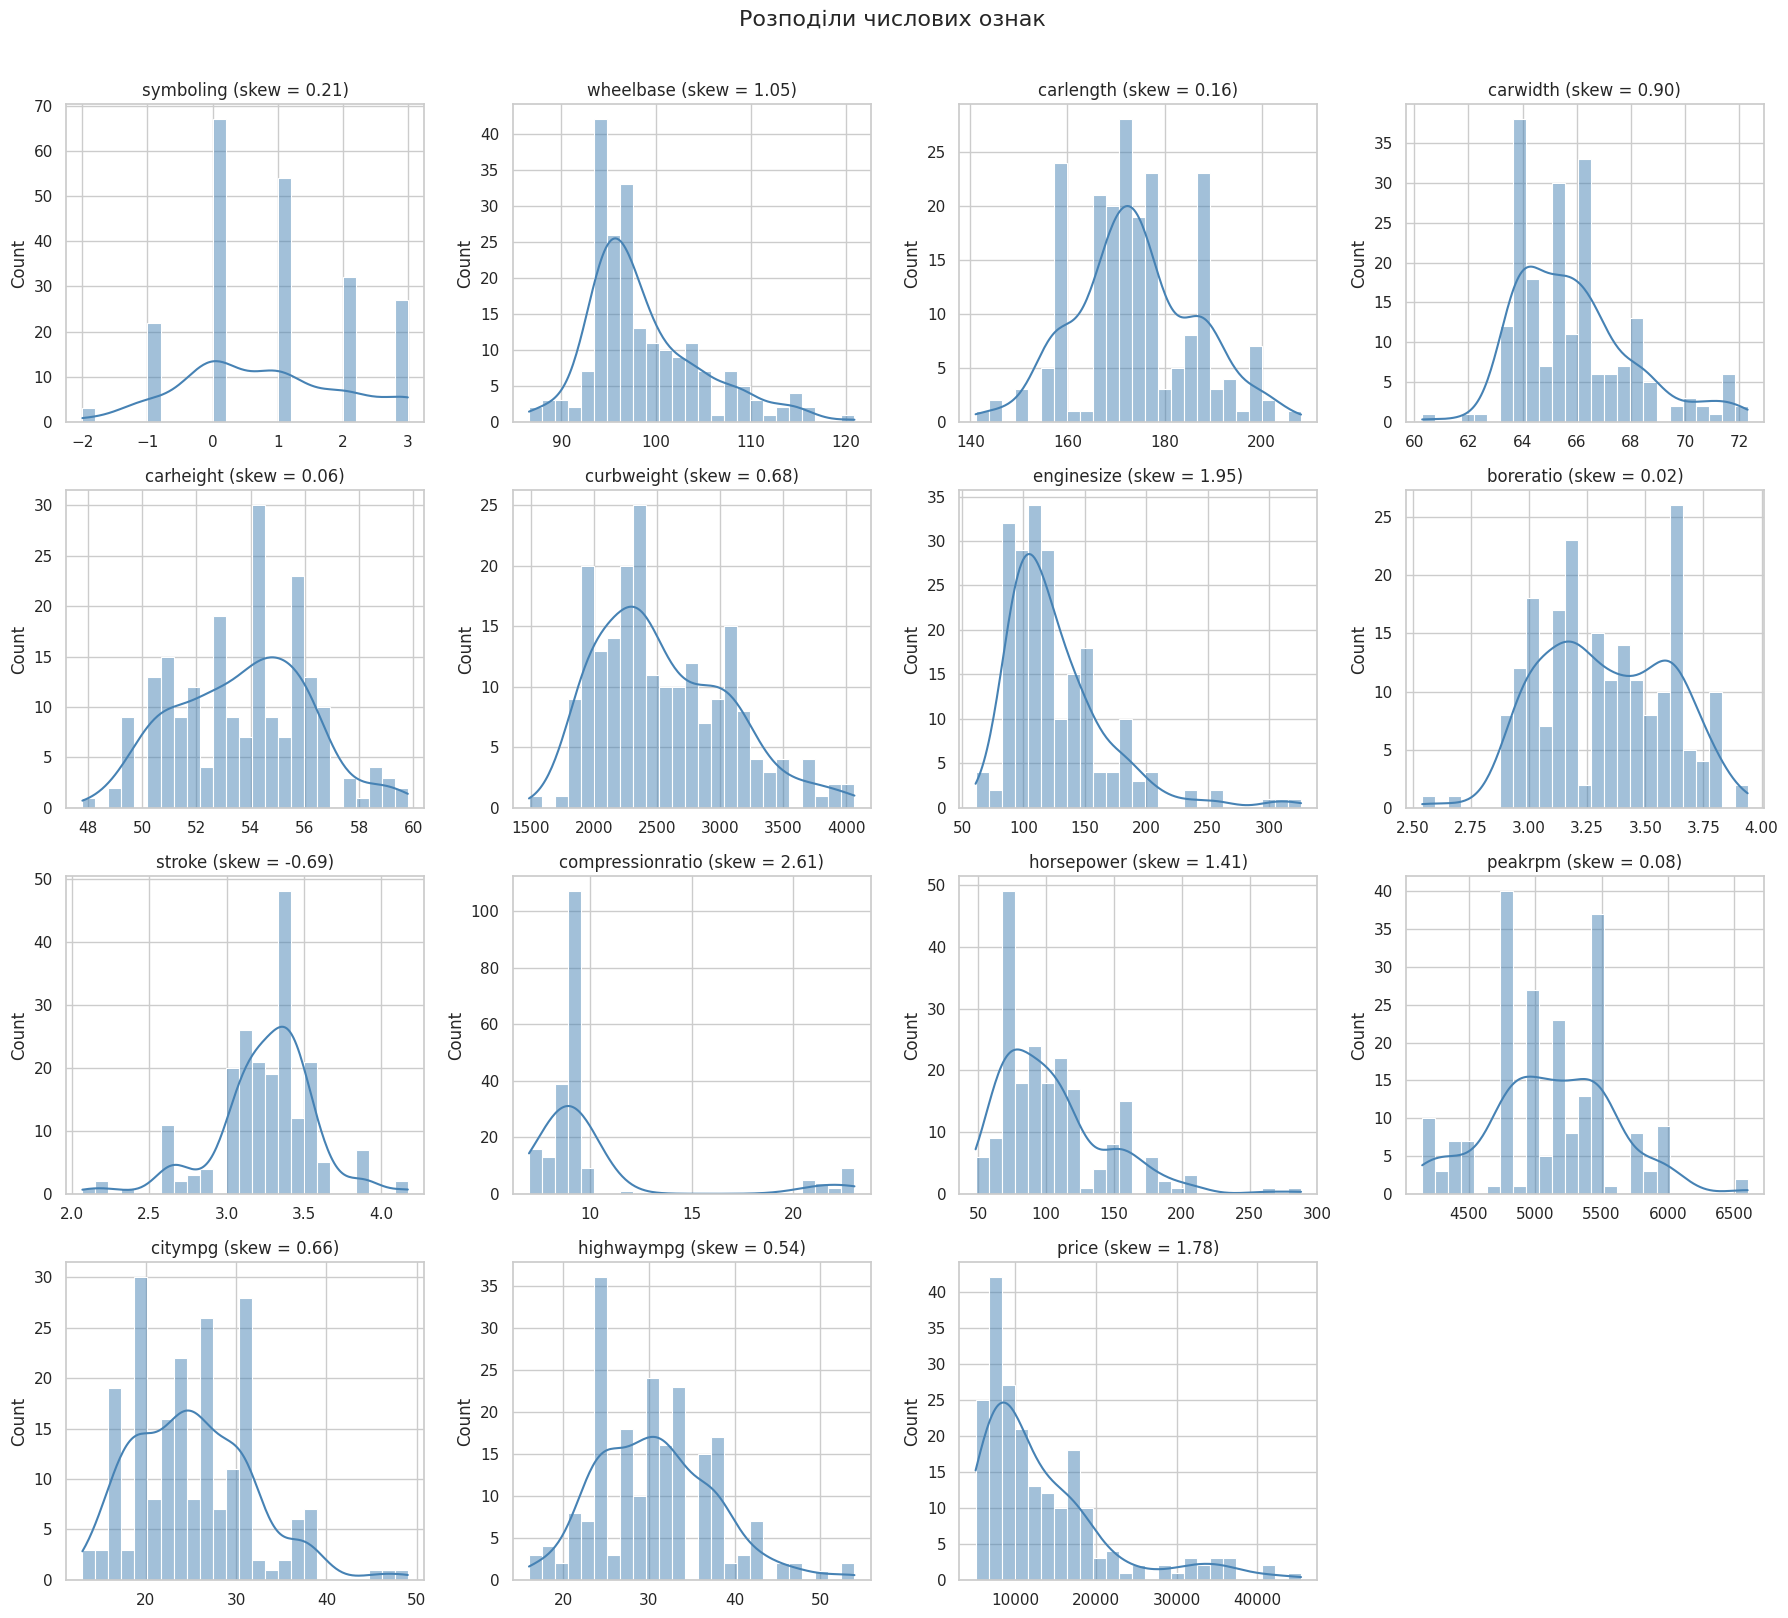

Коефіцієнти асиметрії (за спаданням |skew|):


,Асиметрія (skew),|skew|
compressionratio,2.611,2.611
enginesize,1.948,1.948
price,1.778,1.778
horsepower,1.405,1.405
wheelbase,1.050,1.050
carwidth,0.904,0.904
stroke,-0.690,0.690
curbweight,0.681,0.681
citympg,0.664,0.664
highwaympg,0.540,0.540


Ознаки з найбільш вираженою асиметрією (топ-5):


,Асиметрія (skew),|skew|
compressionratio,2.611,2.611
enginesize,1.948,1.948
price,1.778,1.778
horsepower,1.405,1.405
wheelbase,1.050,1.050


In [ ]:
numeric_cols = df_model.select_dtypes(include="number").columns.tolist()
print("Числові змінні (разом з price):", numeric_cols)

n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df_model[col], kde=True, bins=25, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew = {df_model[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
plt.suptitle("Розподіли числових ознак", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

skew_table = df_model[numeric_cols].skew().to_frame("Асиметрія (skew)")
skew_table["|skew|"] = skew_table["Асиметрія (skew)"].abs()
skew_table = skew_table.sort_values("|skew|", ascending=False)
print("Коефіцієнти асиметрії (за спаданням |skew|):")
display(skew_table.round(3))

print("Ознаки з найбільш вираженою асиметрією (топ-5):")
display(skew_table.head(5).round(3))

**Висновок до етапу 4.** Сильна асиметрія (|skew| > 1) у ознак `compressionratio`, `enginesize`, `price`, `horsepower`, `wheelbase`. Помірна асиметрія (0.5 < |skew| ≤ 1) у `carwidth`, `stroke`, `curbweight`, `citympg`, `highwaympg`. Найбільш скошена ознака — `compressionratio` (skew = 2.61).

Усі сильно скошені ознаки мають додатну асиметрію (довгий правий «хвіст»): більшість автомобілів має невелику ціну й середню потужність, а невелика кількість потужних і дорогих авто формує «хвіст» праворуч. Для `compressionratio` правий «хвіст», імовірно, створюють дизельні двигуни з високим ступенем стиснення. Тому для таких ознак доцільно застосувати перетворення Yeo–Johnson. Цільова змінна `price` теж скошена, але її не перетворюємо: модель прогнозує ціну в початкових одиницях.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

TARGET = "price"

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

car_id_train = car_ids.loc[X_train.index]
car_id_test = car_ids.loc[X_test.index]

print(f"Усього об'єктів: {len(X)}")
print(f"Train: {X_train.shape} ({len(X_train) / len(X):.0%}), Test: {X_test.shape} ({len(X_test) / len(X):.0%})")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")
print(f"car_id_train: {car_id_train.shape}, car_id_test: {car_id_test.shape}")
print(f"Перетин індексів train і test: {len(set(X_train.index) & set(X_test.index))}")
print(f"car_ID серед ознак: {'car_ID' in X_train.columns}")

Усього об'єктів: 205
Train: (164, 24) (80%), Test: (41, 24) (20%)
y_train: (164,), y_test: (41,)
car_id_train: (164,), car_id_test: (41,)
Перетин індексів train і test: 0
car_ID серед ознак: False


**Висновок до етапу 5.** Дані поділено на навчальну (164 авто) і тестову (41 авто) вибірки у співвідношенні 80/20 з `random_state=42`. Вибірки не перетинаються, `car_ID` збережено окремо для кожної з них. Усі параметри передобробки далі визначаються лише за `X_train`, а `X_test` використовується тільки для фінальної оцінки якості.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


Неперервні числові ознаки: ['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Дискретна числова ознака: ['symboling']
Категоріальні ознаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'CarBrand']

Потенційні викиди за методом IQR (train):


,Нижня межа,Верхня межа,Викидів знизу,Викидів зверху,Всього викидів,"Частка, %"
compressionratio,7.400,10.600,4,16,20,12.20
stroke,2.660,3.860,11,5,16,9.76
carwidth,60.425,70.425,0,10,10,6.10
horsepower,4.750,182.750,0,7,7,4.27
enginesize,33.500,205.500,0,7,7,4.27
wheelbase,83.100,113.500,0,6,6,3.66
peakrpm,3750.000,6550.000,0,2,2,1.22
highwaympg,11.500,47.500,0,1,1,0.61
boreratio,2.565,4.125,1,0,1,0.61
curbweight,998.625,4103.625,0,0,0,0.00


Рядків train, що містять хоча б один викид: 50 з 164

Значень змінено в train: 70; у test: 25


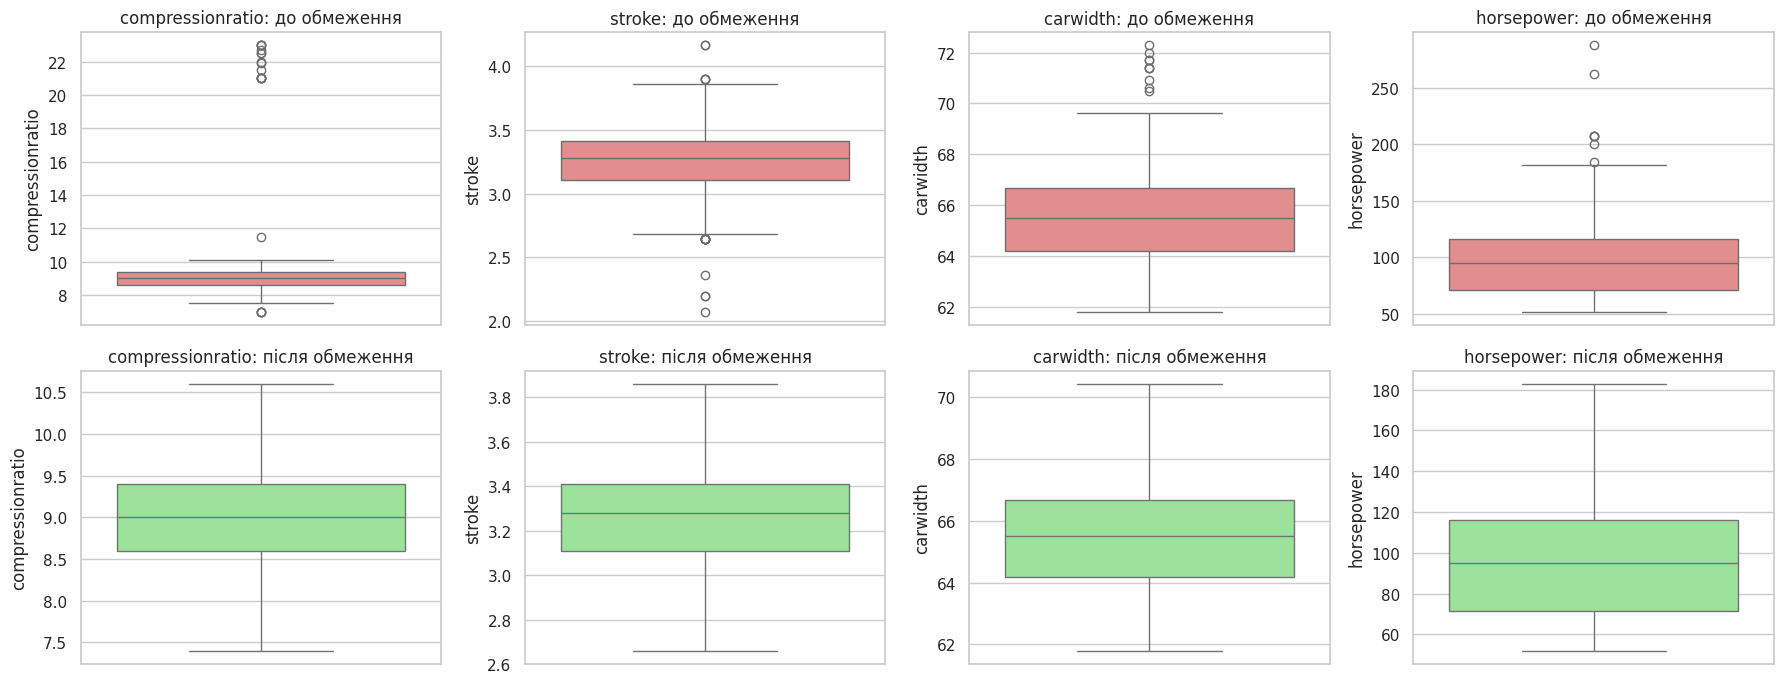

In [ ]:
discrete_features = ["symboling"]
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
continuous_features = [c for c in numeric_features if c not in discrete_features]
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Неперервні числові ознаки:", continuous_features)
print("Дискретна числова ознака:", discrete_features)
print("Категоріальні ознаки:", categorical_features)

q1 = X_train[continuous_features].quantile(0.25)
q3 = X_train[continuous_features].quantile(0.75)
iqr = q3 - q1
lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr

below = X_train[continuous_features] < lower_bounds
above = X_train[continuous_features] > upper_bounds
is_outlier = below | above

outlier_table = pd.DataFrame({
    "Нижня межа": lower_bounds,
    "Верхня межа": upper_bounds,
    "Викидів знизу": below.sum(),
    "Викидів зверху": above.sum(),
    "Всього викидів": is_outlier.sum(),
    "Частка, %": (is_outlier.mean() * 100).round(2),
}).sort_values("Всього викидів", ascending=False)

print("\nПотенційні викиди за методом IQR (train):")
display(outlier_table.round(3))
print(f"Рядків train, що містять хоча б один викид: {is_outlier.any(axis=1).sum()} з {len(X_train)}")

X_train_clipped = X_train.copy()
X_test_clipped = X_test.copy()
X_train_clipped[continuous_features] = X_train[continuous_features].clip(
    lower=lower_bounds, upper=upper_bounds, axis=1
)
X_test_clipped[continuous_features] = X_test[continuous_features].clip(
    lower=lower_bounds, upper=upper_bounds, axis=1
)

test_changed = (X_test[continuous_features] != X_test_clipped[continuous_features]).sum().sum()
train_changed = (X_train[continuous_features] != X_train_clipped[continuous_features]).sum().sum()
print(f"\nЗначень змінено в train: {train_changed}; у test: {test_changed}")

top_features = outlier_table.head(4).index.tolist()
fig, axes = plt.subplots(2, len(top_features), figsize=(4.5 * len(top_features), 7))
for j, col in enumerate(top_features):
    sns.boxplot(y=X_train[col], ax=axes[0, j], color="lightcoral")
    axes[0, j].set_title(f"{col}: до обмеження")
    sns.boxplot(y=X_train_clipped[col], ax=axes[1, j], color="lightgreen")
    axes[1, j].set_title(f"{col}: після обмеження")
plt.tight_layout()
plt.show()

**Висновок до етапу 6.** Викиди знайдено в ознаках `compressionratio`, `stroke`, `carwidth`, `horsepower`, `enginesize`, `wheelbase`, `peakrpm`, `highwaympg`, `boreratio`; найбільше їх у `compressionratio` (20 значень). Навчальна вибірка невелика (164 рядки), а хоча б один викид містить 30% рядків, тому їх видалення призвело б до втрати значної частки даних. До того ж такі значення, імовірно, є реальними автомобілями (дизельні двигуни, потужні моделі), а не помилками вимірювання. Тому застосовано обмеження (winsorization) значень межами IQR: об'єкти залишаються у вибірці, а вплив екстремальних значень на моделі зменшується. Межі визначено лише за train і без використання `price`; ті самі межі застосовано до test.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


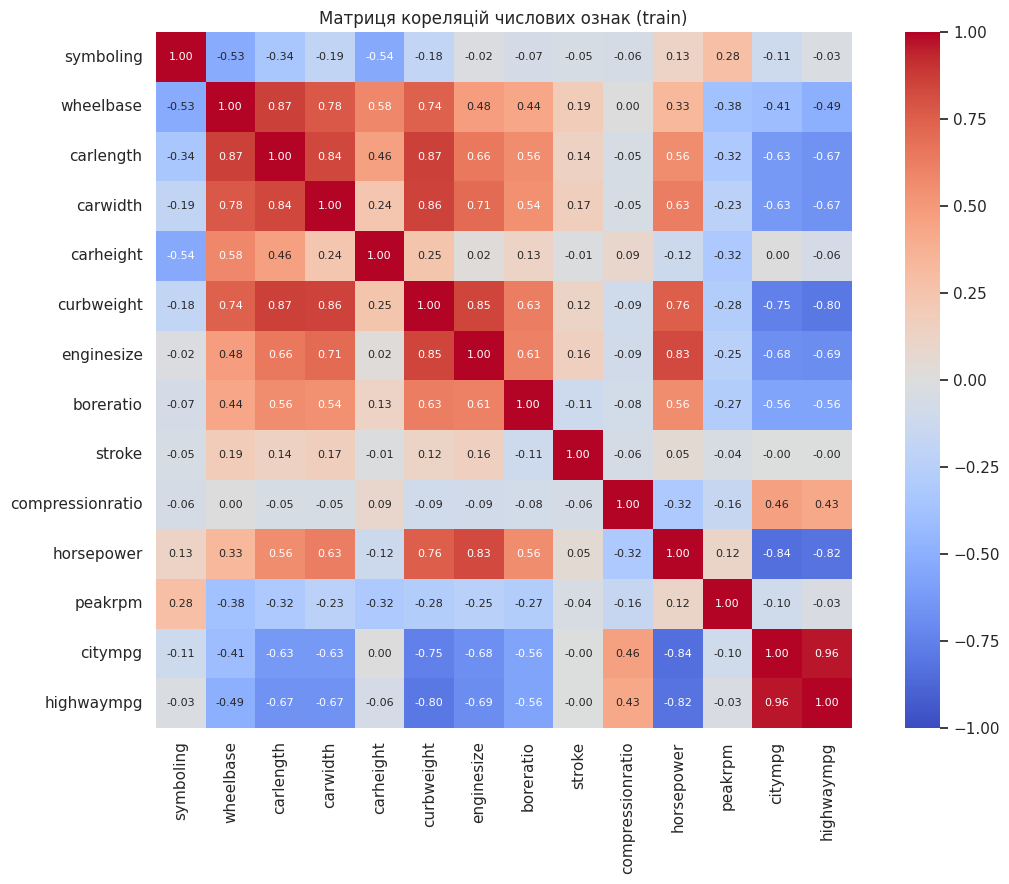

Пари ознак із |r| > 0.85:


,Ознака 1,Ознака 2,r,|r| з price (1),|r| з price (2),Видаляємо
0,citympg,highwaympg,0.964,0.711,0.716,citympg
1,wheelbase,carlength,0.867,0.504,0.652,wheelbase
2,carlength,curbweight,0.866,0.652,0.824,carlength
3,carwidth,curbweight,0.858,0.732,0.824,carwidth


Ознаки, які видаляються: ['citympg', 'wheelbase', 'carlength', 'carwidth']

Ознак було: 24, стало: 20
Максимальна |r| між числовими ознаками, що залишилися: 0.849
Ознаки, що залишилися: ['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg', 'CarBrand']


In [ ]:
corr_matrix = X_train_clipped[numeric_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, annot_kws={"size": 8}, square=True,
)
plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

CORR_THRESHOLD = 0.85

corr_with_price = X_train_clipped[numeric_features].corrwith(y_train).abs()

pairs = []
for i, f1 in enumerate(numeric_features):
    for f2 in numeric_features[i + 1:]:
        r = corr_matrix.loc[f1, f2]
        if abs(r) > CORR_THRESHOLD:
            pairs.append((f1, f2, r))
pairs.sort(key=lambda p: abs(p[2]), reverse=True)

features_to_drop = []
pair_rows = []
for f1, f2, r in pairs:
    if f1 in features_to_drop or f2 in features_to_drop:
        dropped = "вже видалено раніше"
    else:
        dropped = f1 if corr_with_price[f1] < corr_with_price[f2] else f2
        features_to_drop.append(dropped)
    pair_rows.append({
        "Ознака 1": f1,
        "Ознака 2": f2,
        "r": round(r, 3),
        "|r| з price (1)": round(corr_with_price[f1], 3),
        "|r| з price (2)": round(corr_with_price[f2], 3),
        "Видаляємо": dropped,
    })

print(f"Пари ознак із |r| > {CORR_THRESHOLD}:")
display(pd.DataFrame(pair_rows))
print("Ознаки, які видаляються:", features_to_drop)

X_train_sel = X_train_clipped.drop(columns=features_to_drop)
X_test_sel = X_test_clipped.drop(columns=features_to_drop)

remaining_numeric = [c for c in numeric_features if c not in features_to_drop]
remaining_corr = X_train_sel[remaining_numeric].corr().abs()
max_remaining = remaining_corr.where(~np.eye(len(remaining_numeric), dtype=bool)).max().max()

print(f"\nОзнак було: {X_train_clipped.shape[1]}, стало: {X_train_sel.shape[1]}")
print(f"Максимальна |r| між числовими ознаками, що залишилися: {max_remaining:.3f}")
print("Ознаки, що залишилися:", X_train_sel.columns.tolist())

**Висновок до етапу 7.** Знайдено 4 пари ознак із |r| > 0.85. Це розмірні характеристики та вага автомобіля (`wheelbase`, `carlength`, `carwidth`, `curbweight`) і показники витрати палива (`citympg`, `highwaympg`), які значною мірою дублюють одна одну. Із кожної пари збережено ознаку з сильнішим зв'язком із `price`, видалено 4 ознаки: `citympg`, `wheelbase`, `carlength`, `carwidth`. Це зменшує мультиколінеарність, яка робить коефіцієнти лінійних моделей нестабільними. Після відбору найбільша |r| між числовими ознаками становить 0.849, тобто не перевищує порогу. Рішення прийнято тільки за train, з test видалено ті самі стовпці.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

continuous_final = [c for c in continuous_features if c in X_train_sel.columns]
discrete_final = [c for c in discrete_features if c in X_train_sel.columns]
categorical_final = [c for c in categorical_features if c in X_train_sel.columns]

print("Неперервні числові ознаки:", continuous_final)
print("Дискретна числова ознака:", discrete_final)
print("Категоріальні ознаки:", categorical_final)

continuous_transformer = Pipeline(steps=[
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler()),
])

discrete_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", continuous_transformer, continuous_final),
        ("discrete", discrete_transformer, discrete_final),
        ("categorical", categorical_transformer, categorical_final),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

preprocessor.fit(X_train_sel)

X_train_prep = preprocessor.transform(X_train_sel)
X_test_prep = preprocessor.transform(X_test_sel)

print(f"\nФорма X_train після передобробки: {X_train_prep.shape}")
print(f"Форма X_test після передобробки:  {X_test_prep.shape}")
print(f"Кількість пропусків після передобробки: train={X_train_prep.isna().sum().sum()}, test={X_test_prep.isna().sum().sum()}")

unseen_found = False
for col in categorical_final:
    unseen = sorted(set(X_test_sel[col].unique()) - set(X_train_sel[col].unique()))
    if unseen:
        unseen_found = True
        print(f"У test є категорії, яких не було в train ({col}): {unseen} -> закодовано нулями")
if not unseen_found:
    print("У test немає категорій, яких не було в train (handle_unknown='ignore' все одно захищає від помилок).")

print("\nПерші рядки X_train після передобробки (перші 10 стовпців):")
display(X_train_prep.iloc[:3, :10].round(3))

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова ознака: ['symboling']
Категоріальні ознаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'CarBrand']

Форма X_train після передобробки: (164, 69)
Форма X_test після передобробки:  (41, 69)
Кількість пропусків після передобробки: train=0, test=0
У test є категорії, яких не було в train (cylindernumber): ['three'] -> закодовано нулями

Перші рядки X_train після передобробки (перші 10 стовпців):


,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,highwaympg,symboling
66,0.283,0.456,0.540,0.42,1.470,1.998,-0.962,-1.945,1.292,-0.727
111,1.204,1.063,0.102,0.53,-2.023,-0.845,0.011,-0.286,-1.035,-0.727
153,2.152,-0.440,-1.148,-1.01,-0.885,-0.058,-1.560,-0.696,1.012,-0.727


**Висновок до етапу 8.** Побудовано єдиний `ColumnTransformer`: неперервні ознаки (9) проходять Yeo–Johnson і `StandardScaler`, `symboling` лише масштабується, категоріальні ознаки (10) кодуються One-Hot. Параметри (λ для Yeo–Johnson, середні й відхилення, список категорій) знайдено лише за `X_train`. До test застосовано `transform` без повторного навчання. Категорії, яких не було в train (наприклад, `cylindernumber = three`), кодуються нулями й не спричиняють помилки. Після кодування отримано 69 ознак.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


Порівняння асиметрії неперервних ознак (train):


,Skew до,Skew після,|Skew| до,|Skew| після,Зміна |skew|
enginesize,0.962,0.045,0.962,0.045,-0.918
horsepower,0.851,0.066,0.851,0.066,-0.784
curbweight,0.712,0.050,0.712,0.050,-0.663
stroke,-0.398,0.016,0.398,0.016,-0.382
highwaympg,0.244,-0.012,0.244,0.012,-0.232
boreratio,0.063,-0.006,0.063,0.006,-0.057
compressionratio,0.056,0.005,0.056,0.005,-0.051
peakrpm,0.040,-0.004,0.040,0.004,-0.036
carheight,0.028,-0.005,0.028,0.005,-0.023


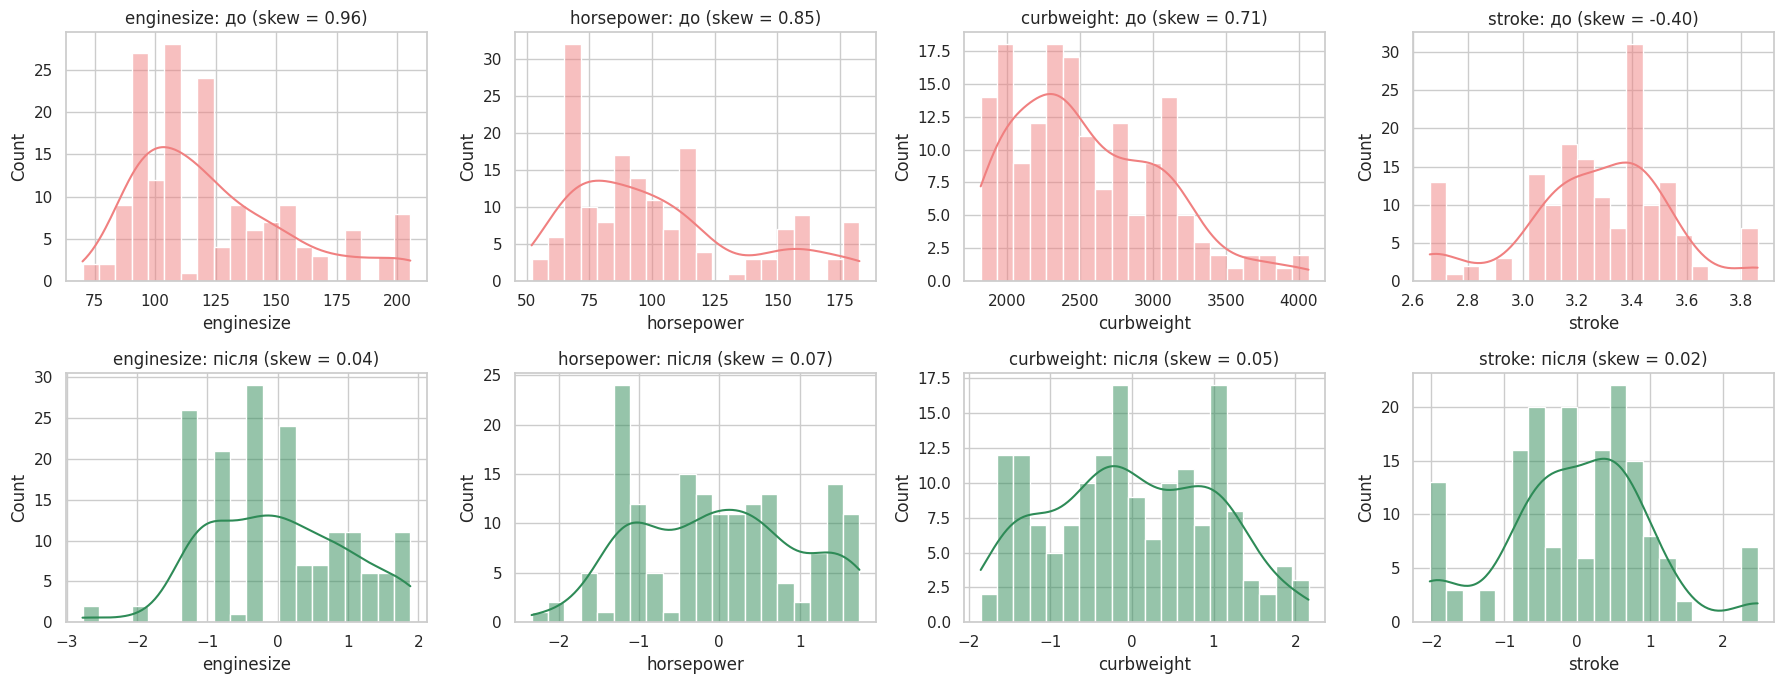

In [ ]:
fitted_continuous = preprocessor.named_transformers_["continuous"]

before = X_train_sel[continuous_final]
after = pd.DataFrame(
    np.asarray(fitted_continuous.transform(before)),
    columns=continuous_final,
    index=before.index,
)

skew_compare = pd.DataFrame({
    "Skew до": before.skew(),
    "Skew після": after.skew(),
})
skew_compare["|Skew| до"] = skew_compare["Skew до"].abs()
skew_compare["|Skew| після"] = skew_compare["Skew після"].abs()
skew_compare["Зміна |skew|"] = skew_compare["|Skew| після"] - skew_compare["|Skew| до"]
skew_compare = skew_compare.sort_values("|Skew| до", ascending=False)

print("Порівняння асиметрії неперервних ознак (train):")
display(skew_compare.round(3))

top4 = skew_compare.head(4).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(top4):
    sns.histplot(before[col], kde=True, ax=axes[0, j], color="lightcoral", bins=20)
    axes[0, j].set_title(f"{col}: до (skew = {before[col].skew():.2f})")
    sns.histplot(after[col], kde=True, ax=axes[1, j], color="seagreen", bins=20)
    axes[1, j].set_title(f"{col}: після (skew = {after[col].skew():.2f})")
plt.tight_layout()
plt.show()

**Висновок до етапу 9.** Середнє |skew| неперервних ознак: 0.915 у вихідному train, 0.373 після обмеження викидів і 0.023 після Yeo–Johnson + StandardScaler. Частину асиметрії (зокрема `compressionratio`) вже зменшило обмеження викидів. Після трансформації асиметрія зменшилась у 9 із 9 ознак. Найбільш скошені ознаки (`enginesize`, `horsepower`, `curbweight`, `stroke`) стали значно симетричнішими, а `StandardScaler` привів усі ознаки до однакового масштабу. Отже, перетворення Yeo–Johnson було ефективним.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.svm import SVR

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=1.0, max_iter=20000),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    ),
    "SVR": TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=10, epsilon=0.1),
        transformer=StandardScaler(),
    ),
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("model", regressor),
    ])
    for name, regressor in regressors.items()
}

for name, pipe in pipelines.items():
    pipe.fit(X_train_sel, y_train)
    print(f"Навчено: {name}")

print("\nСтруктура Pipeline (на прикладі Random Forest):")
print(pipelines["Random Forest"])

Навчено: Linear Regression
Навчено: Ridge Regression
Навчено: Lasso Regression
Навчено: Random Forest
Навчено: Gradient Boosting
Навчено: SVR

Структура Pipeline (на прикладі Random Forest):
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('continuous',
                                                  Pipeline(steps=[('yeo_johnson',
                                                                   PowerTransformer(standardize=False)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['carheight', 'curbweight',
                                                   'enginesize', 'boreratio',
                                                   'stroke', 'compressionratio',
                                                   'horsepower', 'peakrpm',
                                              

**Висновок до етапу 10.** Побудовано та навчено 6 моделей: Linear, Ridge, Lasso, Random Forest, Gradient Boosting і SVR. Кожна модель — це `Pipeline` з однаковою передобробкою (обмеження викидів і відбір ознак виконано раніше, Yeo–Johnson + StandardScaler + One-Hot — усередині `Pipeline`) та власним регресором. Параметри передобробки для кожного `Pipeline` визначаються лише за `X_train`, тому порівняння моделей коректне.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

predictions = {}
results = []

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test_sel)
    predictions[name] = y_pred
    results.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
    })

results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1

print("Порівняння моделей на тестовій вибірці (за R² від найбільшого до найменшого):")
display(results_df.style.format({"R²": "{:.4f}", "MAE": "{:,.2f}", "MSE": "{:,.0f}", "MAPE, %": "{:.2f}"}))

overfit_df = results_df[["Модель", "R²"]].rename(columns={"R²": "R² test"})
overfit_df["R² train"] = [r2_score(y_train, pipelines[m].predict(X_train_sel)) for m in overfit_df["Модель"]]
overfit_df["Різниця (train - test)"] = overfit_df["R² train"] - overfit_df["R² test"]
print("\nПеревірка перенавчання (R² на train і test):")
display(overfit_df[["Модель", "R² train", "R² test", "Різниця (train - test)"]].style.format(
    {"R² train": "{:.4f}", "R² test": "{:.4f}", "Різниця (train - test)": "{:.4f}"}
))

Порівняння моделей на тестовій вибірці (за R² від найбільшого до найменшого):


,Модель,R²,MAE,MSE,"MAPE, %"
1,Random Forest,0.9554,"1,311.09","3,519,785",9.64
2,Gradient Boosting,0.9311,"1,688.74","5,442,891",11.46
3,SVR,0.9294,"1,668.31","5,574,315",15.54
4,Linear Regression,0.8794,"2,156.10","9,518,236",16.38
5,Lasso Regression,0.8782,"2,105.21","9,612,671",15.13
6,Ridge Regression,0.8538,"2,367.22","11,542,488",18.19



Перевірка перенавчання (R² на train і test):


,Модель,R² train,R² test,Різниця (train - test)
1,Random Forest,0.9851,0.9554,0.0297
2,Gradient Boosting,0.9957,0.9311,0.0646
3,SVR,0.9881,0.9294,0.0587
4,Linear Regression,0.9597,0.8794,0.0803
5,Lasso Regression,0.9595,0.8782,0.0813
6,Ridge Regression,0.9482,0.8538,0.0944


**Висновок до етапу 11.** Найвищий R² на тестовій вибірці у моделі Random Forest: R² = 0.9554, MAE = 1 311, MAPE = 9.6%. Найгірший результат у Ridge Regression (R² = 0.8538). Для R² краще більше значення, для MAE, MSE і MAPE — менше.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Тип задачі.** Цільова змінна `price` - неперервна числова величина (у даних 189 унікальних цін для 205 автомобілів). Тому прогнозування ціни належить до задачі **регресії**: потрібно передбачити число, а не вибрати клас.

**Чому Logistic Regression не підходить для прогнозу ціни.**

- Незважаючи на назву, логістична регресія - це **класифікатор**. Вона оцінює ймовірності для скінченного набору класів (сигмоїда або softmax) і повертає мітку класу, а не довільне число.
- Якщо вважати кожну ціну окремим класом, то майже кожен автомобіль утворить власний клас (189 унікальних цін із 205 об'єктів). На клас припадатиме приблизно один приклад, модель не навчиться узагальнювати і не зможе передбачити ціну, якої не було в навчальній вибірці.
- Класи не мають порядку та відстані: помилка "41 000 замість 40 000" і "41 000 замість 5 000" для класифікатора однаково "неправильна". Функція втрат логістичної регресії (log loss) не враховує величину помилки, тоді як для ціни важлива саме відстань між прогнозом і фактом. Тому якість оцінюють метриками регресії: R², MAE, MSE, MAPE.
- Розбиття цін на діапазони (дешеві, середні, дорогі) перетворило б задачу на іншу - класифікацію - і призвело б до втрати точності: ми б знали лише діапазон, а не саму ціну.

**Чому використані моделі відповідають задачі регресії.**

- Linear, Ridge і Lasso Regression - лінійні регресійні моделі (мінімізують квадратичну помилку; Ridge додає L2-, а Lasso - L1-регуляризацію), що повертають число як лінійну комбінацію ознак.
- Random Forest Regressor і Gradient Boosting Regressor - ансамблі регресійних дерев: прогноз - це середнє (Random Forest) або сума послідовних поправок (Gradient Boosting) числових значень у листках дерев.
- SVR - регресійна версія методу опорних векторів з epsilon-нечутливою функцією втрат.

Усі ці моделі повертають неперервне значення, а їх якість вимірюється регресійними метриками. **Висновок:** для прогнозування ціни автомобіля коректно застосовувати саме регресійні моделі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


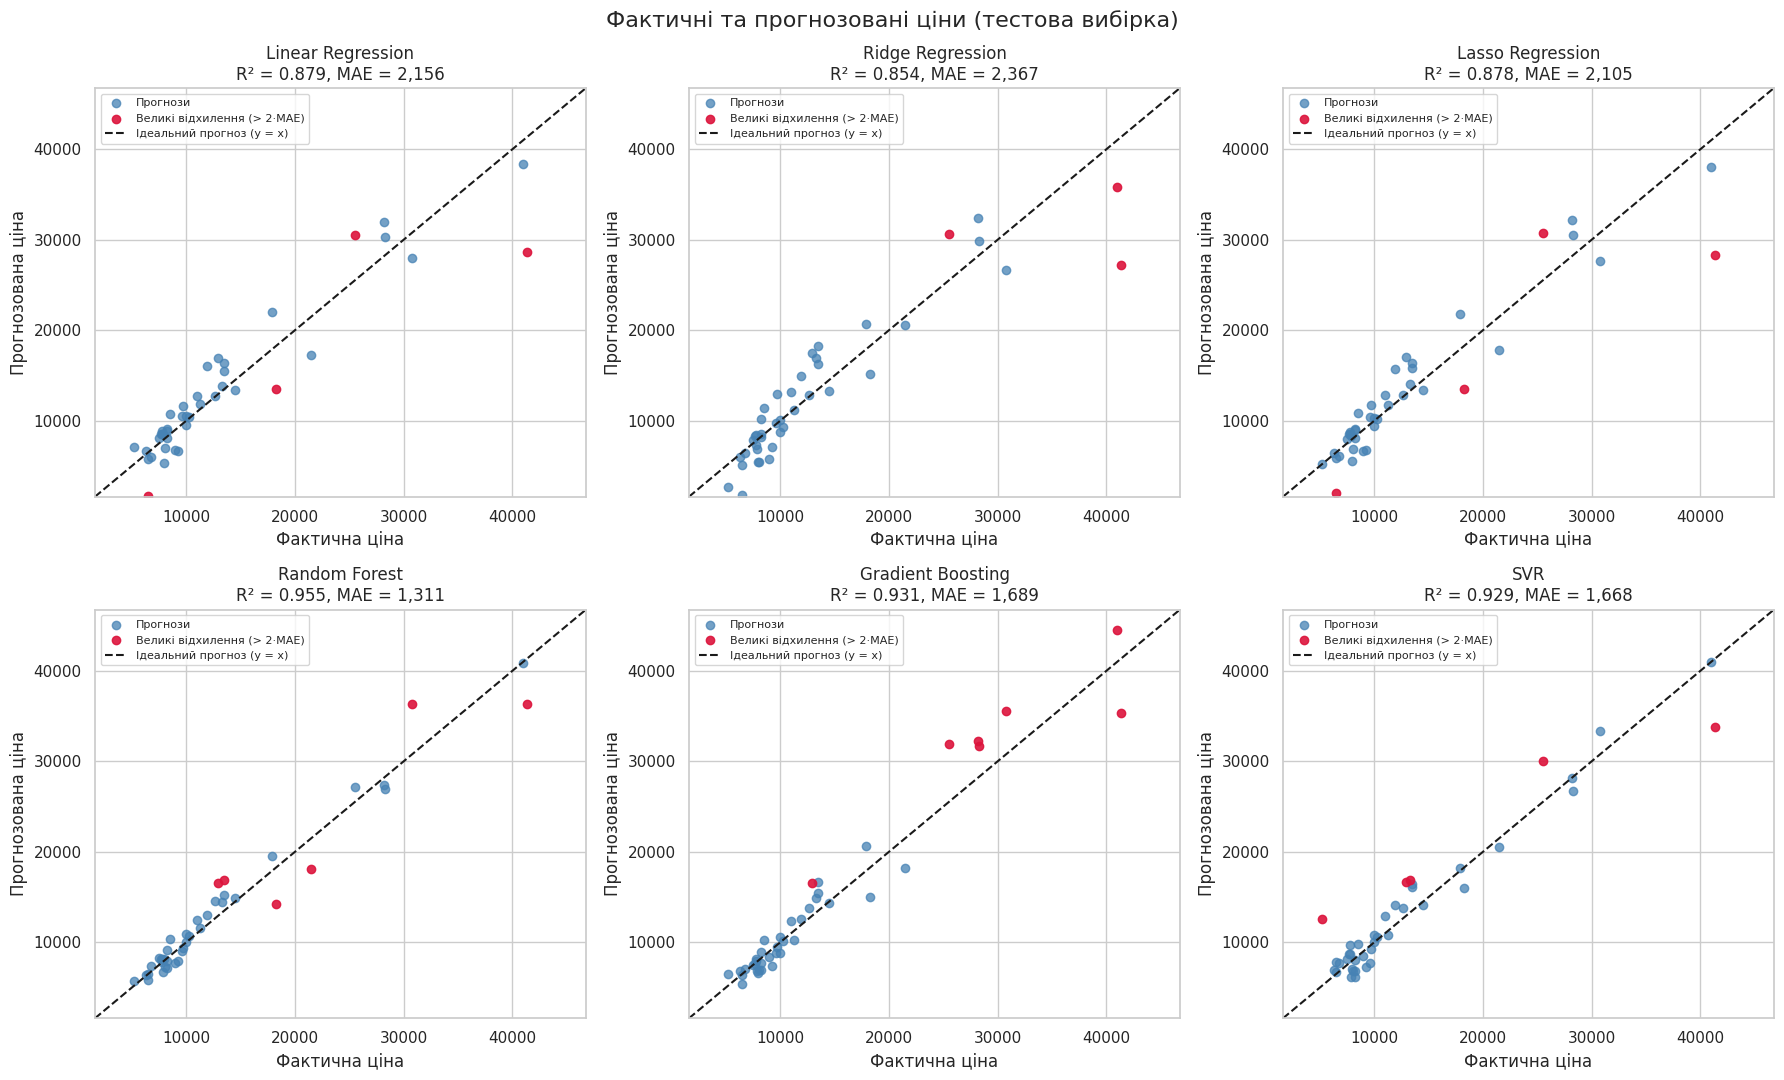

Три найбільші відхилення для кожної моделі:


,Модель,car_ID,Фактична ціна,Прогноз,Абсолютна помилка
0,Linear Regression,17,41315.0,28634.0,12681.0
1,Linear Regression,68,25552.0,30520.0,4968.0
2,Linear Regression,31,6479.0,1664.0,4815.0
3,Ridge Regression,17,41315.0,27195.0,14120.0
4,Ridge Regression,74,40960.0,35825.0,5135.0
5,Ridge Regression,68,25552.0,30621.0,5069.0
6,Lasso Regression,17,41315.0,28267.0,13048.0
7,Lasso Regression,68,25552.0,30742.0,5190.0
8,Lasso Regression,66,18280.0,13535.0,4745.0
9,Random Forest,16,30760.0,36383.0,5623.0


Кількість моделей (з 6), у яких авто має велике відхилення (показано авто, що повторюються у 3+ моделях):


,Кількість моделей
car_ID,
17,6
68,5
66,3
195,3


In [ ]:
y_true = y_test.to_numpy()
lims = [min(y_true.min(), min(p.min() for p in predictions.values())) * 0.95,
        max(y_true.max(), max(p.max() for p in predictions.values())) * 1.05]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
large_error_ids = []
deviation_rows = []

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    abs_error = np.abs(y_true - y_pred)
    is_large = abs_error > 2 * abs_error.mean()

    ax.scatter(y_true[~is_large], y_pred[~is_large], alpha=0.75, color="steelblue", label="Прогнози")
    ax.scatter(y_true[is_large], y_pred[is_large], alpha=0.9, color="crimson", label="Великі відхилення (> 2·MAE)")
    ax.plot(lims, lims, "k--", linewidth=1.5, label="Ідеальний прогноз (y = x)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.set_title(f"{name}\nR² = {r2_score(y_true, y_pred):.3f}, MAE = {abs_error.mean():,.0f}")
    ax.legend(loc="upper left", fontsize=8)

    large_error_ids.extend(car_id_test.to_numpy()[is_large].tolist())
    for idx in np.argsort(abs_error)[::-1][:3]:
        deviation_rows.append({
            "Модель": name,
            "car_ID": car_id_test.iloc[idx],
            "Фактична ціна": y_true[idx],
            "Прогноз": y_pred[idx],
            "Абсолютна помилка": abs_error[idx],
        })

plt.suptitle("Фактичні та прогнозовані ціни (тестова вибірка)", fontsize=16)
plt.tight_layout()
plt.show()

print("Три найбільші відхилення для кожної моделі:")
display(pd.DataFrame(deviation_rows).round(0).astype({"car_ID": int}))

large_counts = pd.Series(large_error_ids).value_counts()
repeated = large_counts[large_counts >= 3]
print("Кількість моделей (з 6), у яких авто має велике відхилення (показано авто, що повторюються у 3+ моделях):")
display(repeated.rename("Кількість моделей").to_frame().rename_axis("car_ID"))

**Висновок до етапу 13.** Точки всіх моделей групуються навколо лінії ідеального прогнозу, тобто моделі загалом відтворюють залежність ціни від ознак. Найкраще узгодження з лінією має Random Forest (R² = 0.955), найгірше — лінійні моделі з найнижчим R². Найбільші відхилення стосуються дорогих автомобілів: авто з `car_ID = 17` (фактична ціна 41 315) має велике відхилення в усіх 6 моделей, і всі моделі занижують його ціну. Імовірно, дорогих автомобілів у навчальній вибірці мало, тому моделям важко прогнозувати ціни на межі діапазону. Лінійні моделі також іноді дають нереалістично низькі прогнози для дешевих авто (наприклад, `car_ID = 31`: фактична ціна 6 479, а Linear Regression прогнозує близько 1 664).

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
sample_idx = X_test_sel.sample(n=10, random_state=RANDOM_STATE).index

rf_pipeline = pipelines["Random Forest"]
rf_pred = rf_pipeline.predict(X_test_sel.loc[sample_idx])

sample_table = pd.DataFrame({
    "car_ID": car_id_test.loc[sample_idx].to_numpy(),
    "Фактична ціна": y_test.loc[sample_idx].to_numpy(),
    "Прогнозована ціна": rf_pred,
})
sample_table["Абсолютна помилка"] = (sample_table["Фактична ціна"] - sample_table["Прогнозована ціна"]).abs()
sample_table["Абсолютна відсоткова помилка, %"] = (
    sample_table["Абсолютна помилка"] / sample_table["Фактична ціна"] * 100
)
sample_table.index = sample_table.index + 1

print("Прогноз Random Forest для 10 випадкових автомобілів з тестової вибірки:")
display(sample_table.style.format({
    "Фактична ціна": "{:,.2f}",
    "Прогнозована ціна": "{:,.2f}",
    "Абсолютна помилка": "{:,.2f}",
    "Абсолютна відсоткова помилка, %": "{:.2f}",
}))

print(f"Середня абсолютна помилка у вибірці: {sample_table['Абсолютна помилка'].mean():,.2f}")
print(f"Середня абсолютна відсоткова помилка: {sample_table['Абсолютна відсоткова помилка, %'].mean():.2f}%")
print(f"Максимальна відсоткова помилка: {sample_table['Абсолютна відсоткова помилка, %'].max():.2f}% (car_ID = {sample_table.loc[sample_table['Абсолютна відсоткова помилка, %'].idxmax(), 'car_ID']})")

Прогноз Random Forest для 10 випадкових автомобілів з тестової вибірки:


,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
1,26,"6,692.00","7,322.24",630.24,9.42
2,176,"9,988.00","10,929.02",941.02,9.42
3,148,"10,198.00","10,695.45",497.45,4.88
4,17,"41,315.00","36,368.71","4,946.29",11.97
5,69,"28,248.00","26,909.69","1,338.31",4.74
6,147,"7,463.00","8,294.29",831.29,11.14
7,144,"9,960.00","10,062.71",102.71,1.03
8,85,"14,489.00","14,825.76",336.76,2.32
9,195,"12,940.00","16,563.30","3,623.30",28.00
10,160,"7,788.00","7,827.16",39.16,0.50


Середня абсолютна помилка у вибірці: 1,328.65
Середня абсолютна відсоткова помилка: 8.34%
Максимальна відсоткова помилка: 28.00% (car_ID = 195)


**Висновок до етапу 14.** Random Forest прогнозує ціни випадкових автомобілів досить точно: середня абсолютна відсоткова помилка становить 8.3%, а у 9 з 10 авто помилка не перевищує 15%. Найбільша відносна помилка у `car_ID = 195` (28.0%): фактична ціна 12 940, прогноз 16 563. Найбільша абсолютна помилка у `car_ID = 17` (4 946), проте для дорогого авто це лише 12.0% від ціни. Для більшості авто абсолютні помилки невеликі, але похибка нерівномірна: окремі автомобілі (зокрема `car_ID = 195` середньої цінової категорії) прогнозуються помітно гірше за інші. Це узгоджується з MAPE моделі на всій тестовій вибірці (близько 9.6%).

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**1. Порівняння моделей.** Результати на тестовій вибірці (41 автомобіль), впорядковані за R²:

| Модель | R² | MAE | MSE | MAPE, % |
|---|---|---|---|---|
| Random Forest | 0.9554 | 1 311 | 3 519 785 | 9.64 |
| Gradient Boosting | 0.9311 | 1 689 | 5 442 891 | 11.46 |
| SVR | 0.9294 | 1 668 | 5 574 315 | 15.54 |
| Linear Regression | 0.8794 | 2 156 | 9 518 236 | 16.38 |
| Lasso Regression | 0.8782 | 2 105 | 9 612 671 | 15.13 |
| Ridge Regression | 0.8538 | 2 367 | 11 542 488 | 18.19 |

**2. Найкраща модель.** Random Forest показав найкращі результати за всіма чотирма метриками одночасно: найбільший R² (0.955) і найменші MAE, MSE та MAPE. Gradient Boosting і SVR мають близькі між собою R² (0.931 і 0.929), тому на малій тестовій вибірці розрізнити їх надійно не можна. Лінійні моделі (Linear, Lasso, Ridge) помітно слабші: R² близько 0.85-0.88 та найбільші помилки. Ймовірно, залежність ціни від ознак нелінійна (наприклад, ціна непропорційно зростає для потужних і великих автомобілів), і ансамблі дерев та SVR з нелінійним ядром її описують краще.

**3. Величина похибок.** Для Random Forest MAE становить близько 1 311, а MAPE - 9.6%, тобто в середньому прогноз відхиляється від фактичної ціни приблизно на десяту частину. Для 10 випадково вибраних авто середня відсоткова помилка склала 8.3%, а найбільша - 28% (car_ID = 195). Найбільші абсолютні помилки припадають на дорогі автомобілі: авто з car_ID = 17 (41 315) занижують усі шість моделей. MAPE чутливий до помилок на дешевих авто: SVR має MAE на рівні Gradient Boosting, але вищий MAPE (15.5% проти 11.5%) через великі відносні помилки для кількох дешевих автомобілів (наприклад, car_ID = 19).

**4. Ознаки перенавчання.** Для всіх моделей R² на train вищий, ніж на test. Різниця (train - test): Random Forest - 0.030 (0.985 -> 0.955), Gradient Boosting - 0.065 (0.996 -> 0.931), SVR - 0.059, Linear і Lasso - близько 0.08, Ridge - 0.094. Gradient Boosting і SVR майже ідеально підганяються під train (R² близько 0.99), тому для них є помірні ознаки перенавчання. У лінійних моделей великий розрив пояснюється малою вибіркою (164 об'єкти) при 69 ознаках після One-Hot кодування. Найменший розрив у Random Forest, і він же найкращий на test, тож серйозного перенавчання за цією моделлю не видно. Слід враховувати, що тестова вибірка мала (41 об'єкт), тому оцінки метрик мають помітну невизначеність. Для надійнішого висновку варто застосувати крос-валідацію і підбір гіперпараметрів (наприклад, alpha для Ridge і Lasso, глибини дерев, C для SVR).

**5. Вплив попередньої обробки.** Усі параметри передобробки визначали лише за навчальною вибіркою, тому оцінка на test не містить витоку інформації. Обмеження викидів за межами IQR змінило 70 значень у train, але зберегло всі 164 об'єкти. Відбір ознак за кореляцією прибрав чотири ознаки (citympg, wheelbase, carlength, carwidth) і зменшив мультиколінеарність. Перетворення Yeo-Johnson разом зі StandardScaler зменшило середню абсолютну асиметрію неперервних ознак приблизно з 0.37 до 0.02. Це особливо важливо для лінійних моделей, Ridge, Lasso та SVR, чутливих до масштабу й розподілу ознак, тоді як дерева (Random Forest, Gradient Boosting) до масштабу нечутливі. One-Hot кодування з handle_unknown="ignore" дозволило обробити категорію (cylindernumber = three), якої не було в train. Порівняння з варіантом без передобробки в роботі не проводилося, тому оцінка її впливу якісна, а не кількісна.

**Загальний підсумок.** Для прогнозування ціни автомобіля на цьому датасеті найкращою виявилась модель Random Forest (R² = 0.955, MAPE = 9.6%). Вона давала найточніші прогнози і мала найменший розрив між якістю на навчальних та тестових даних, тому її доцільно використовувати як основну модель.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
